# ASTR 457: The Midterm

Posted Thu Oct 8, due Wed Oct 14 by Noon (fork → PR, as always). Graded like a lab.

Three parts. Each is designed to test something every lab so far has come back to - which error bar is the right one, whether the model needs the extra parameter, and whether the check you ran could have failed. You've now got the tools to do all of this, so let's do it on numbers you haven't seen: 250 real Type Ia supernovae, and someone else's analysis of real white dwarfs.

Part 1 is 30 pts (6 each), Part 2 is 45 pts, and Part 3 is 25 pts. You'll need 2b and 2c right to get 2d right.

Remember, the rules are the syllabus rules - open book, you can use AI tools (document them in 3b), you can work together and discuss problems and solutions, but you have to write up your own solution and run it on **your own data** in `data/<your netid>/` (nobody else's numbers will match yours).

Put your notebook in `submissions/<your netid>/midterm.ipynb`. The path below (`DATA`) reaches your files from there. Make sure it runs top to bottom from a fresh kernel ("Restart & Run All") - that is how it will be graded, and how it will be run if you defend it.

Throughout, make sure every number you quote has a unit, an error bar and a sensible number of digits (two significant figures on the error bar, and round the value to match).

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

NETID = 'oruelas2'   # <-- set this
DATA = f'../../labs/midterm/data/{NETID}/'   # from submissions/<your netid>/

def load(name):
    """Read one of your CSV files as a pandas table; d['column'].to_numpy() gives a numpy array. Names stay strings."""
    return pd.read_csv(DATA + name + '.csv', dtype={'name': str})

In [112]:
from astropy.cosmology import FlatLambdaCDM
import emcee
import corner
from IPython.display import display, Math
import arviz as az

## Part 1: Error bars (30 pts, 6 each)

Five short scenarios. Each one is a number someone handed you - say whether it's right, compute the right one, and say in a sentence or two why. Show the code. Each of these should be about 20 minutes of work.

### 1a - The extinction coefficient (`p1a_extinction.csv`)

An observer measured a photometric zero point at 15 different airmasses through one night. Extinction in magnitudes grows in proportion to the airmass $X$, so the zero point should follow a line, $m = k\,X + m_0$, where $k$ is the extinction coefficient in mag per airmass. Columns: `airmass`, `zeropoint_mag`, `sigma_quoted_mag` (the pipeline's error on each point).

1. Fit the line by weighted least squares with the quoted errors. Report $k$ and its error bar computed from the quoted errors alone.
2. Now run `np.polyfit(airmass, zeropoint_mag, 1, w=1/sigma_quoted_mag, cov=True)` and report its error bar on $k$. Explain exactly what `polyfit` did to get a different number (read its documentation for `cov`).
3. Compute $\chi^2$ and the number of degrees of freedom. How probable is a $\chi^2$ this large or this small if the quoted errors were right? (Compute it from the $\chi^2$ distribution.)
4. Report the error bar on $k$ you'd quote, and justify it. What does your answer to (3) tell you about the pipeline's error bars?

In [113]:
# 1a: your work here
d1a = load('p1a_extinction')
d1a[:5]

,airmass,zeropoint_mag,sigma_quoted_mag
0,1.01675,25.0009,0.018698
1,1.02414,25.0221,0.013145
2,1.12340,25.0230,0.013450
3,1.15877,25.0330,0.012778
4,1.32119,25.0524,0.010551


In [114]:
X, m, sig_1a = d1a['airmass'].to_numpy(), d1a['zeropoint_mag'].to_numpy(), d1a['sigma_quoted_mag'].to_numpy()

In [115]:
#1 
def wls(A, y, err):
    n = len(y)
    w = 1.0 / (err**2)
    AtwA_inv = np.linalg.inv(A.T @ (A * w[:, None]))
    theta = AtwA_inv @ A.T @ (y * w)
    return theta, AtwA_inv

A = np.vstack([np.ones_like(X), X]).T
theta, cov = wls(A, m, sig_1a)
mo, k = theta
mo_err, k_err = np.sqrt(np.diag(cov))

print(f'k wls = {k:.3f} +/- {k_err:.3f} mag/airmass')

k wls = 0.129 +/- 0.010 mag/airmass


In [116]:
#2
fit = np.polyfit(X, m, 1, w=1/sig_1a, cov=True)
vals, cov_fit = fit
k_fit, mo_fit = vals
kfit_err, mofit_err = np.sqrt(np.diag(cov_fit))

print(f'k np.polyfit = {k_fit:.4f} +/- {kfit_err:.4f} mag/airmass')

k np.polyfit = 0.1288 +/- 0.0044 mag/airmass


In [117]:
#3
dof = len(d1a) - 2
resid = m - np.polyval([k, mo], X)
chi2 = np.sum((resid / sig_1a)**2)

print(f'degrees of freedom = {dof:.0f}')
print(f'chi2 = {chi2:.2f}')

degrees of freedom = 13
chi2 = 2.67


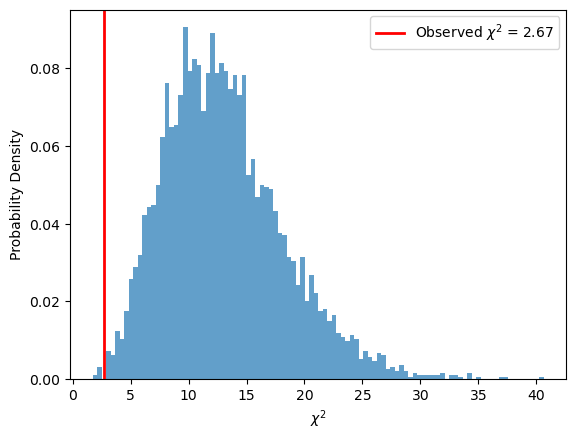

p-value = 1.00


In [118]:
chi2_obs = chi2
nu = dof

rng = np.random.default_rng(42)
chi2_samples = np.sum(rng.normal(size=(5000, nu))**2, axis=1)

p_value = np.mean(chi2_samples >= chi2_obs)

plt.hist(chi2_samples, bins=100, density=True, alpha=0.7)
plt.axvline(chi2_obs, color="red", lw=2,
            label=fr"Observed $\chi^2$ = {chi2_obs:.2f}")
plt.xlabel(r"$\chi^2$")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

print(f"p-value = {p_value:.2f}")

**ANSWER:** K error = $\pm$ 0.0044 mag/airmass

The np.polyfit results in a smaller error from the covariance since the values are scaled by chi2/dof to achieve a reduced chi2 that is unity (~1). If the errors were calculated correctly, a chi2 this small is unlikely compared to the distribution. The chi2 distribution and calculated p value suggest overestimation of the pipeline's error bars. Because of this I have decided to report the np.polyfit error bar on k, since the WLS error is closer aligned with the pipeline error.

### 1b - The centroid (`p1b_centroid.csv`)

A classmate measured the position of a star from `n_photons` photons, each landing at a position drawn from a Gaussian of width `psf_sigma_arcsec` around the true position. They report an error on the position of `quoted_sigma_x0_arcsec`, from a clever weighting scheme they found online.

1. Compute the Cramér-Rao bound on the error of any unbiased estimator of the position (Lab 02).
2. Is the quoted error possible? If not, say what the classmate's number must mean instead, and name two concrete mistakes that would produce an error bar this small.

In [119]:
# 1b: your work here
d1b = load('p1b_centroid')
d1b

,psf_sigma_arcsec,n_photons,quoted_sigma_x0_arcsec
0,1.56385,377,0.061469


In [120]:
sig_arcsec, n_photons, quoted_sig = d1b['psf_sigma_arcsec'].to_numpy(), d1b['n_photons'].to_numpy(), d1b['quoted_sigma_x0_arcsec'].to_numpy()

In [121]:
#1
sigma_cr = sig_arcsec / np.sqrt(n_photons)
print(f'Is the quoted error within the bound? : {(quoted_sig >= sigma_cr)[0]}')
print(f'Ratio = {(quoted_sig / sigma_cr)[0]:.2f}')

Is the quoted error within the bound? : False
Ratio = 0.76


**ANSWER:**

The quoted error is not within the Cramér-Rao bound. The ratio of the error and bound being 0.76 suggests bias from the estimator since the Cramér-Rao bound is the smallest variance that can be achieved by an unbiased estimator. The bias this estimator has is likely due to background photons, which is something seen when calculating the error from variance in lab02. 

### 1c - The transit depth's error bar (`p1c_profile.csv`)

A transit-depth fit produced this profile: columns `depth_ppt` (the depth, in parts per thousand) and `minus2lnL` ($-2\ln L$ at that depth, other parameters fixed at their best values). A classmate took the second derivative of `minus2lnL` at its minimum and reported $\sigma = 1/\sqrt{d^2(-2\ln L)/d\,\textrm{depth}^2}$.

1. Find the best depth and the correct $1\sigma$ error from the curvature. Is the classmate's error bar right? If not, by what factor is it off, and why?
2. Read the $\Delta(-2\ln L) = 1$ interval directly off the profile. Is it symmetric? Compare it with your curvature answer.
3. If the classmate quotes $\pm$ their $\sigma$ on many independent datasets, what fraction of those intervals contain the true depth? Predict it, then check it with a simulation (a few thousand fake best-fit depths drawn around a truth you choose, using your correct $\sigma$).

In [122]:
# 1c: your work here
d1c = load('p1c_profile')
d1c[:5]

,depth_ppt,minus2lnL
0,1.62587,112.577
1,1.65058,112.006
2,1.67530,111.444
3,1.70002,110.892
4,1.72473,110.349


In [123]:
depth, m2lnL = d1c['depth_ppt'].to_numpy(), d1c['minus2lnL'].to_numpy()

In [124]:
#1
io = np.argmin(m2lnL)
depth_best = depth[io]

nfit = 5
lo = max(0, io - nfit)
hi = min(len(depth), io + nfit + 1)

coef = np.polyfit(depth[lo:hi], m2lnL[lo:hi], 2)
a, b, c = coef

depth_best = -b / (2 * a)

curve = 2 * a

sigma = np.sqrt(2.0 / curve)

class_sig = sigma / np.sqrt(2)

print(f'Classmate simga = {class_sig:.2f} ppt')
print(f'Best depth = {depth_best:.2f} ppt')
print(f'Correct sigma = {sigma:.2f} ppt')

Classmate simga = 0.17 ppt
Best depth = 2.61 ppt
Correct sigma = 0.25 ppt


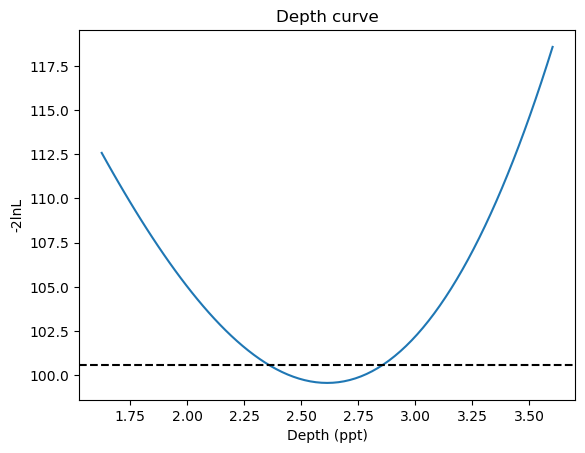

In [125]:
#2
plt.plot(depth, m2lnL)
plt.axhline(y=m2lnL.min() + 1, color='k', linestyle='--')
plt.title('Depth curve'), plt.xlabel('Depth (ppt)'), plt.ylabel('-2lnL')
plt.show()

In [126]:
#3
rng = np.random.default_rng(101126)
Nsim = 5000

depth_sim = rng.normal(depth_best, sigma, Nsim)

inside = np.abs(depth_sim - depth_best) <= class_sig

frac_inside = np.mean(inside)

print(f'Simulations = {Nsim}')
print(f'Fraction within ±1σ of truth = {frac_inside:.4f}')
print(f'Percent within ±1σ of truth = {100*frac_inside:.2f}%')

Simulations = 5000
Fraction within ±1σ of truth = 0.5184
Percent within ±1σ of truth = 51.84%


**ANSWER:**

The classmate's error bar is missing a factor of square root 2 from taking the second derivative. The $\Delta(-2\ln L) = 1$ interval (2.35, 2.85) is not symmetric. Since the minimum point is ~2.6 on the graph which is in line with the best depth that I calculated. If my classmate quotes $\pm$ their $\sigma$ on many independent datasets I think that the truth will be captured less than the ~68% expected interval due to the classmate error bar being off by the factor of 2. This is the case as shown by the calculated 51.84% interval.

### 1d - The companion mass (`p1d_mass_samples.csv`)

These are 8000 posterior samples of the mass of an unseen companion, `M2_Msun`. Three classmates report its uncertainty as (i) the variance of the samples, (ii) the 84th percentile minus the 16th, and (iii) the standard deviation divided by $\sqrt{8000}$.

1. Report the mass as a median with its 16th-84th percentile error bars, in solar masses.
2. For each of (i)-(iii): what quantity is it actually, what are its units, and by roughly what factor is it wrong as a $1\sigma$ error bar?
3. Is a symmetric $\pm$ error bar appropriate for this posterior? If not, show why.

In [127]:
# 1d: your work here
d1d = load('p1d_mass_samples')
d1d[:5]

,M2_Msun
0,5.77408
1,6.22080
2,13.56470
3,9.02170
4,8.48114


In [128]:
M2 = d1d['M2_Msun'].to_numpy()

In [129]:
#1
M2_med = np.median(M2)
p16, p50, p84 = np.percentile(M2, [16, 50, 84])
M2_err = ((p50-p16) + (p84-p50))/2

print(f'Companion Mass = {M2_med:.2f} +/- {M2_err:.2f} solar masses')

Companion Mass = 8.05 +/- 1.88 solar masses


In [130]:
#2
one = np.mean((M2 - M2_med)**2)
two = np.percentile(M2, 84) - np.percentile(M2, 16)
three = (np.std(M2) / np.sqrt(8000))

print(f'i uncertainty = {one:.2f}')
print(f'ii uncertainty = {two:.2f}')
print(f'iii uncertainty = {three:.3f}')

i uncertainty = 3.81
ii uncertainty = 3.75
iii uncertainty = 0.022


In [131]:
print(f' i uncertainty / true uncertainty = {one/M2_err:.2f}')
print(f' ii uncertainty / true uncertainty = {two/M2_err:.2f}')
print(f' iii uncertainty / true uncertainty = {three/M2_err:.3f}')

 i uncertainty / true uncertainty = 2.03
 ii uncertainty / true uncertainty = 2.00
 iii uncertainty / true uncertainty = 0.012


In [132]:
print(f'{(p50-p16):.3f}, {(p84-p50):.3f}')
print(f'{(p84-p50) - (p50-p16):.3f}')

1.687, 2.067
0.380


**ANSWER:** Companion Mass = 8.05 $\pm$ 1.88 solar masses

The (i) uncertainty from the variance is actually the error bar squared. The (ii) uncertainty from the 84th minus the 16th percentile is twice the size of the true error bar. The (iii) uncertainty the standard deviation divided by $\sqrt{8000}$ is the error on the sample mean. A symmetric error bar is appropriate for this posterior because there is not a significant difference in the 16th-84th percentile error bars. 

### 1e - The slope at fixed intercept (`p1e_slope_intercept_samples.csv`)

Posterior samples of a slope and an intercept from a line fit. A classmate fixed the intercept at its best value, refit only the slope, and quoted the slope's error from that 1-D fit.

1. Compute the slope's error bar the classmate got (the spread of the slope *at fixed intercept*), and the marginal one (the spread of the slope with the intercept marginalized over).
2. Compute their ratio, and the correlation coefficient $\rho$ of the samples. How does the ratio depend on $\rho$? Plot the samples and draw both error bars on the plot.
3. When is the classmate's number the right one to quote? One sentence.

In [133]:
# 1e: your work here
d1e = load('p1e_slope_intercept_samples')
d1e[:5]

,slope,intercept
0,1.36040,-0.061821
1,1.30770,0.502887
2,1.20270,1.361820
3,1.23335,0.977267
4,1.23493,0.810234


In [134]:
m, b = d1e['slope'].to_numpy(), d1e['intercept'].to_numpy()

In [135]:
#1 
p16, p50, p84 = np.percentile(m, [16, 50, 84])
m_err = ((p50-p16) + (p84-p50))/2

cov = np.cov(m, b)

var_m = cov[0, 0]
var_b = cov[1, 1]
cov_mb = cov[0, 1]

var_fixed_b = var_m - cov_mb**2 / var_b
m_fixed = np.sqrt(var_fixed_b)

print(f"Classmate error: {m_fixed:.3f}")
print(f'Marginalized error = {m_err:.3f}')

Classmate error: 0.021
Marginalized error = 0.052


In [136]:
#2
corr = cov_mb / np.sqrt(var_m * var_b)
print(f'Ratio = {m_fixed/m_err:.2f}')
print(f'Correlation coefficient = {corr:.2f}')

Ratio = 0.40
Correlation coefficient = -0.92


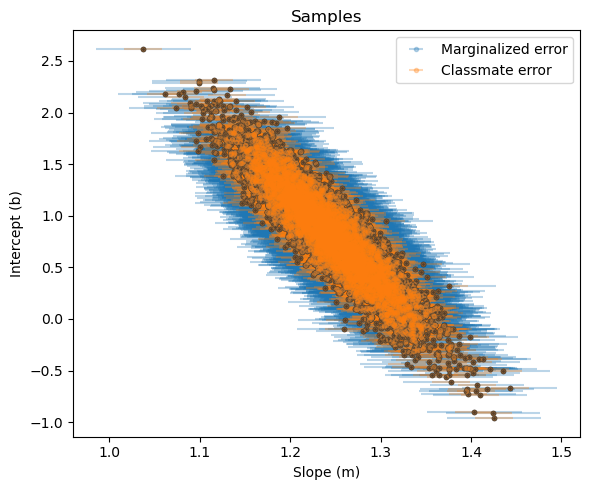

In [137]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.errorbar(m, b, xerr=m_err, fmt='.', alpha=0.3, label='Marginalized error')
ax.errorbar(m, b, xerr=m_fixed, fmt='.', alpha=0.3, label='Classmate error')
ax.plot(m, b, ".", color='k')

ax.set_title("Samples"), ax.set_xlabel("Slope (m)"), ax.set_ylabel("Intercept (b)")
ax.legend()
plt.tight_layout()
plt.show()

**ANSWER:**

There is a strong negative correlation between slope and intercept based on the coefficient and plot. The classmate error is the right one to quote when slope and intercept are not correlated.

## Part 2: 250 supernovae and a step (45 pts)

Type Ia supernovae are standardizable candles: their peak brightness, corrected for how fast they fade and for their color, measures distance well enough to have discovered cosmic acceleration. Your file `p2_pantheon_sne.csv` holds 250 real SNe Ia from the Pantheon+ compilation (Scolnic et al. 2022, ApJ 938, 113; [Brout et al. 2022](https://arxiv.org/abs/2202.04077), ApJ 938, 110), all at redshift $0.023 < z < 0.15$. For each supernova, a light-curve fit (SALT2) gives:

- `mB`: the peak apparent magnitude in the B band, and `mB_err`;
- `x1`: the light-curve *stretch* (broader light curves are brighter), and `x1_err`;
- `c`: the *color* (redder supernovae are fainter, from dust and intrinsically), and `c_err`;
- `cov_mB_x1`, `cov_mB_c`, `cov_x1_c`: the covariances between those three, from the same light-curve fit;
- `z`: the redshift; `host_logmass`, `host_logmass_err`: $\log_{10}$ of the host galaxy's stellar mass in solar masses, and its error.

The standardized brightness is the **Tripp relation**,

$$m_B = M + \mu(z) - \alpha\,x_1 + \beta\,c + \gamma\,\Theta(\log M_\star - 10),$$

where $M$ is the absolute magnitude of a "standard" SN Ia, $\mu(z)$ the distance modulus, $\Theta$ is 1 for hosts more massive than $10^{10}\,M_\odot$ and 0 otherwise, and $\gamma$ is the **host-mass step**. Supernovae in massive hosts appear to be brighter after standardization (Kelly et al. 2010; Sullivan et al. 2010); whether the step is real, and why, matters for supernova dark-energy measurements. In this form, a step that makes supernovae in massive hosts brighter has $\gamma < 0$; the published value is about $\gamma \approx -0.06$ mag. So the question for your sample is whether you need $\gamma$ at all.

There are two more things you'll need. At these redshifts the galaxies' own motions (peculiar velocities, about 250 km/s) shift $z$, and so $\mu$; add $\sigma_{\mu,\rm pec} = \frac{5}{\ln 10}\frac{250\ {\rm km/s}}{c\,z}$ to each supernova's variance. And no supernova is a perfect standard candle: add an intrinsic scatter $\sigma_{\rm int}$, a free parameter. Use a flat $\Lambda$CDM distance modulus with $H_0 = 70$ km/s/Mpc and $\Omega_m = 0.3$ (`astropy.cosmology.FlatLambdaCDM(H0=70, Om0=0.3).distmod(z)`); $M$ absorbs the choice of $H_0$.

We planted between **two and four contaminants** in your file - objects whose `mB` we made fainter by more than a magnitude, so they are not standard SNe Ia any more (think of a mis-classified peculiar supernova). Their names are not in the file. Real data have a few real outliers too, so not everything far from the line is planted.

### 2a - Look at the data (5 pts)

1. Compute $\mu(z)$ and plot the **Hubble residuals** $m_B - \mu(z)$ against $x_1$, against $c$, and against `host_logmass`.
2. Which way do the $x_1$ and $c$ trends go? Is that the sign the Tripp relation expects? Two or three sentences.
3. The raw trend with host mass may not have the sign of $\gamma$. Why not? (Plot $x_1$ against host mass.)
4. Can you see any of the contaminants?
5. What units do $\alpha$ and $\beta$ have?

In [138]:
# 2a: your work here
data = load('p2_pantheon_sne')
data

,name,z,mB,mB_err,x1,x1_err,c,c_err,cov_mB_x1,cov_mB_c,cov_x1_c,host_logmass,host_logmass_err
0,000137,0.11901,19.6281,0.036931,-0.710055,0.175650,0.081772,0.030635,0.002155,0.000892,0.000521,10.21360,0.035
1,010010,0.09950,19.1455,0.033575,0.909100,0.156590,0.010397,0.026207,0.001055,0.000748,0.000496,9.50285,0.089
2,010026,0.03236,16.4521,0.038223,-0.409321,0.082041,-0.031578,0.032595,0.000854,0.001093,0.000205,9.61222,0.010
3,020027,0.11001,19.3621,0.033575,0.296650,0.150750,0.036283,0.029087,-0.000080,0.000835,-0.000914,10.00540,0.107
4,090275,0.13955,19.8340,0.041261,-1.108370,0.173260,-0.037598,0.032102,0.002230,0.001002,0.000990,10.18400,0.008
...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,SN2017coa,0.04095,16.9721,0.055357,0.711950,0.316610,-0.047302,0.038881,0.003175,0.001651,-0.000647,8.76499,0.030
246,SN2017cpu,0.05502,17.1232,0.043441,0.753230,0.342360,-0.060611,0.037778,-0.001084,0.001373,-0.002317,10.52100,0.001
247,SN2017hn,0.02557,15.6562,0.043266,0.624390,0.215660,-0.027287,0.035539,0.000793,0.001269,-0.000558,10.86340,0.001
248,SN2017ms,0.02591,15.5491,0.037581,0.431880,0.232120,-0.120033,0.033733,0.001916,0.000927,-0.000178,8.61119,0.002


In [139]:
z, mB, mB_err, x1, x1_err, c, c_err, cov_mB_x1, cov_mB_c, cov_x1_c, host_logmass, host_logmass_err = data['z'].to_numpy(), data['mB'].to_numpy(), data['mB_err'].to_numpy(), data['x1'].to_numpy(), data['x1_err'].to_numpy(), data['c'].to_numpy(), data['c_err'].to_numpy(), data['cov_mB_x1'].to_numpy(), data['cov_mB_c'].to_numpy(), data['cov_x1_c'].to_numpy(), data['host_logmass'].to_numpy(), data['host_logmass_err'].to_numpy() 

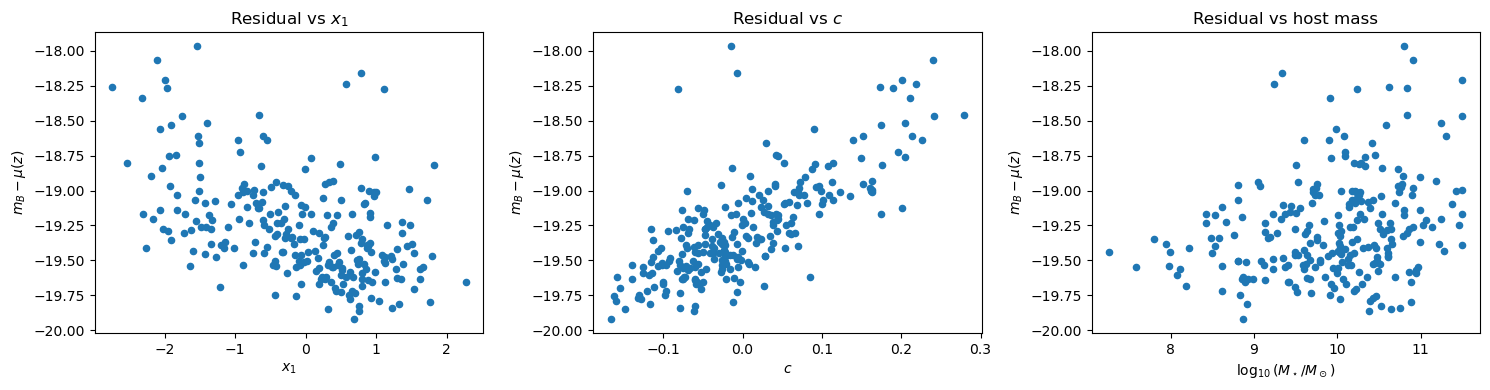

In [140]:
#1
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu = cosmo.distmod(z).value

resid = mB - mu

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].scatter(x1, resid, s=20)
ax[0].set_xlabel(r'$x_1$')
ax[0].set_ylabel(r'$m_B-\mu(z)$')
ax[0].set_title('Residual vs $x_1$')

ax[1].scatter(c, resid, s=20)
ax[1].set_xlabel(r'$c$')
ax[1].set_ylabel(r'$m_B-\mu(z)$')
ax[1].set_title('Residual vs $c$')

ax[2].scatter(host_logmass, resid, s=20)
ax[2].set_xlabel(r'$\log_{10}(M_\star/M_\odot)$')
ax[2].set_ylabel(r'$m_B-\mu(z)$')
ax[2].set_title('Residual vs host mass')

plt.tight_layout()
plt.show()

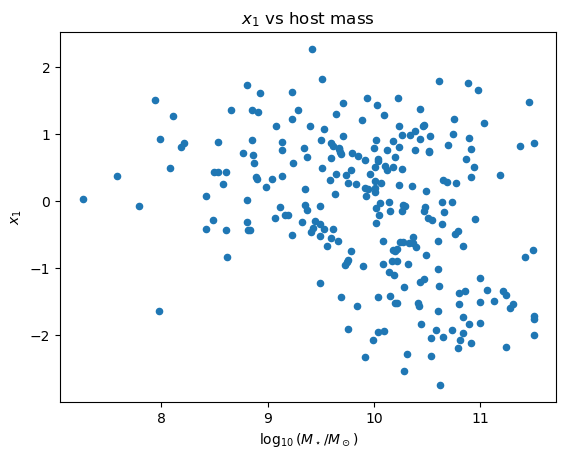

In [141]:
#3 
plt.scatter(host_logmass, x1, s=20)
plt.title('$x_1$ vs host mass'), plt.xlabel(r'$\log_{10}(M_\star/M_\odot)$'), plt.ylabel(r'$x_1$')
plt.show()

**ANSWER:**

In the graphs of my Hubble residuals against $x_1$, $c$, and `host_logmass`, we see a negative (-) trend with $x_1$ and a positive (+) trend with $c$. Based on the Tripp relation these are the signs we expect to see. Looking at $x_1$ against `host_logmass` there is no obvious trend when compared to the residual graphs. Which could explain why we don't see the sign of $\gamma$. While I have my suspicions on possible contaminants I can't say for sure that I see them based on what we have looked at in the data. $\alpha$ and $\beta$ have units of magnitude (mag).

### 2b - The likelihood (10 pts)

The parameters are $\theta = (M, \alpha, \beta, \gamma, \sigma_{\rm int})$. Each supernova's variance is

$$\sigma_i^2 = \mathbf{v}^T C_i\,\mathbf{v} + \sigma_{\mu,{\rm pec},i}^2 + \sigma_{\rm int}^2, \qquad \mathbf{v} = (1, \alpha, -\beta),$$

where $C_i$ is that supernova's $3\times3$ covariance of $(m_B, x_1, c)$.

1. Write out $\mathbf{v}^T C_i\,\mathbf{v}$ term by term, and explain in one sentence why the off-diagonal terms are there.
2. Write the log-likelihood. Remember the $\ln\sigma_i^2$ term - the variance depends on the parameters.
3. State a prior for every parameter, and justify each in one line.
4. Decide whether to sample $\ln\sigma_{\rm int}$ or $\sigma_{\rm int}$, and say why.
5. Decide what to do about the contaminants. You may model them or remove them, but say how you found them and what a cut would cost you.

In [142]:
# 2b: your work here
c_light = 299792.458
sig_mu = (5/np.log(10)) * (250/(c_light*z))
THETA = np.ones_like(host_logmass)

for i in range(len(host_logmass)):
    if host_logmass[i] > 10:
        THETA[i] = 1
    else:
        THETA[i] = 0

In [143]:
def loglikelihood(theta, sig_mu, mB, x1, c, THETA):
    M, a, B, gamma, lnsig_int = theta
    sig_int = np.exp(lnsig_int)
    v = np.array([1.0, a, -B])
    C = mB_err**2 + a**2 * x1_err**2 + B**2 * c_err**2 + 2*a*cov_mB_x1 - 2*B*cov_mB_c - 2*a*B*cov_x1_c
    var = C + sig_mu**2 + sig_int**2

    resid = mB - (M + mu - a*x1 + B*c + gamma*THETA)

    return -0.5 * np.sum(resid**2 / var + np.log(2*np.pi*var))

In [144]:
M = mB - sig_mu
print(f'{np.mean(M):.2f} mag')

17.54 mag


In [145]:
def logprior(theta):
    M, a, B, gamma, lnsig_int = theta

    if (-22 < M < -14) & (-1 < a < 1) & (0 < B < 10) & (-2 < gamma < 2) & (-10 < lnsig_int < 0):
        return 0.0
        
    return -np.inf

**ANSWER:**

$\mathbf{v} = (1, \alpha, -\beta)$,  $\mathbf{C} =\begin{pmatrix}mB_{\rm err}^2 & \mathrm{cov}_{mB,x1} & \mathrm{cov}_{mB,c} \\\mathrm{cov}_{mB,x1} & x1_{\rm err}^2 & \mathrm{cov}_{x1,c} \\\mathrm{cov}_{mB,c} & \mathrm{cov}_{x1,c} & c_{\rm err}^2\end{pmatrix}$, $\mathbf{v}^T =\begin{pmatrix}1\\\alpha\\-\beta\end{pmatrix}$

The off-diagonal terms show if and how the two values correlate. I chose each prior based on expected values to observe for type Ia supernovae and reasonable bounds around those. I am sampling $\ln\sigma_{\rm int}$ since $\sigma_{\rm int}$ is expected to be positive. I will be modeling the contaminants since I do not believe could reliably identify them within the data.

### 2c - Sampling and convergence (12 pts)

1. Find the maximum a posteriori point. Then run **four independent chains** from starting points spread wider than the posterior (you choose how, and say how you chose). Any sampler is fine - your own Metropolis, `emcee` (one ensemble per chain), or `PyMC`.
2. Report $\hat R$ and the effective sample size for every parameter (`arviz.rhat`, `arviz.ess`, or `arviz.summary`), and say what values would have made you run longer.
3. Make a corner plot, and quote $\alpha$, $\beta$, $\gamma$ and $\sigma_{\rm int}$ as medians with 16th-84th percentile error bars.
4. Which parameters are correlated strongly? Comment on why. Then fix $M$ at its MAP value, refit $\gamma$, and compare that $\sigma_\gamma$ with the marginal one (cf. 1e).

`ArviZ` 1.x (install it with `conda install -c conda-forge pymc arviz`, as in `INSTALL.txt`) takes your chains as a dictionary of arrays shaped (chain, draw): `idata = az.from_dict({'posterior': {'alpha': a, 'beta': b}})`, then `az.summary(idata)`.

In [146]:
# 2c: your work here
def logprob(theta, sig_mu, mB, x1, c, THETA):
    lp = logprior(theta)
    
    if not np.isfinite(lp):
        return -np.inf

    return lp + loglikelihood(theta, sig_mu, mB, x1, c, THETA)

def neglogprob(theta, sig_mu, mB, x1, c, THETA):
    lp = logprior(theta)
    
    if not np.isfinite(lp):
        return np.inf

    return - lp - loglikelihood(theta, sig_mu, mB, x1, c, THETA)

In [147]:
theta = [-18, 0.2, 4, 0.5, -0.1]
m = minimize(neglogprob, theta, args = (sig_mu, mB, x1, c, THETA), method='Nelder-Mead')
map_theta = m.x

In [148]:
ndim = 5
nwalkers = 32
nsteps = 5000

scales = np.array([0.5, 0.3, 1.0, 0.2, 0.1])

chains = []

for seed in [1, 2, 3, 4]:

    rng = np.random.default_rng(seed)

    pos = map_theta + scales * rng.normal(size=(nwalkers, ndim))

    sampler = emcee.EnsembleSampler(
        nwalkers,
        ndim,
        logprob,
        args=(sig_mu, mB, x1, c, THETA)
    )

    sampler.run_mcmc(pos, nsteps)

    chains.append(sampler)

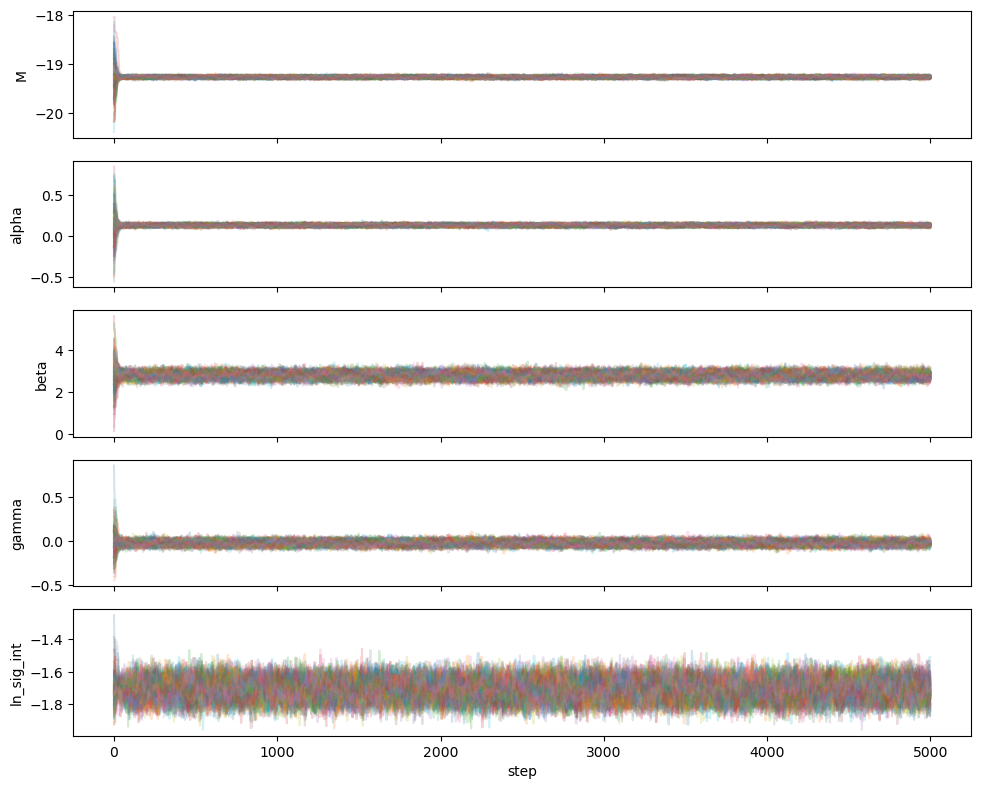

In [149]:
fig, axes = plt.subplots(ndim, 1, figsize=(10, 8), sharex=True)

labels = ["M", "alpha", "beta", "gamma", "ln_sig_int"]

for k in range(ndim):
    for j, sampler in enumerate(chains):
        axes[k].plot(
            sampler.get_chain()[:, :, k],
            alpha=0.2,
            label=f"chain {j+1}" if k == 0 else None
        )

    axes[k].set_ylabel(labels[k])

axes[-1].set_xlabel("step")

plt.tight_layout()
plt.show()

In [150]:
tau = sampler.get_autocorr_time()

samples = np.array([
    sampler.get_chain(discard=100, thin=int((tau.max())/2),flat=False)
    for sampler in chains
])

In [151]:
M_chain = samples[:, :, :, 0].reshape(4, -1)
a_chain = samples[:, :, :, 1].reshape(4, -1)
B_chain = samples[:, :, :, 2].reshape(4, -1)
gamma_chain = samples[:, :, :, 3].reshape(4, -1)
sigint_chain = np.exp(samples[:, :, :, 4].reshape(4, -1))

print("R-hat:")
print(f'M = {az.rhat(M_chain):.2f}')
print(f'alpha = {az.rhat(a_chain):.2f}')
print(f'beta = {az.rhat(B_chain):.2f}')
print(f'gamma = {az.rhat(gamma_chain):.2f}')
print(f'sig_int = {az.rhat(sigint_chain):.2f}')

print("\nESS:")
print(f'M = {az.ess(M_chain):.2f}')
print(f'alpha = {az.ess(a_chain):.2f}')
print(f'beta = {az.ess(B_chain):.2f}')
print(f'gamma = {az.ess(gamma_chain):.2f}')
print(f'sig_int = {az.ess(sigint_chain):.2f}')

R-hat:
M = 1.00
alpha = 1.00
beta = 1.00
gamma = 1.00
sig_int = 1.00

ESS:
M = 21185.61
alpha = 23509.61
beta = 22990.89
gamma = 22825.92
sig_int = 22561.68


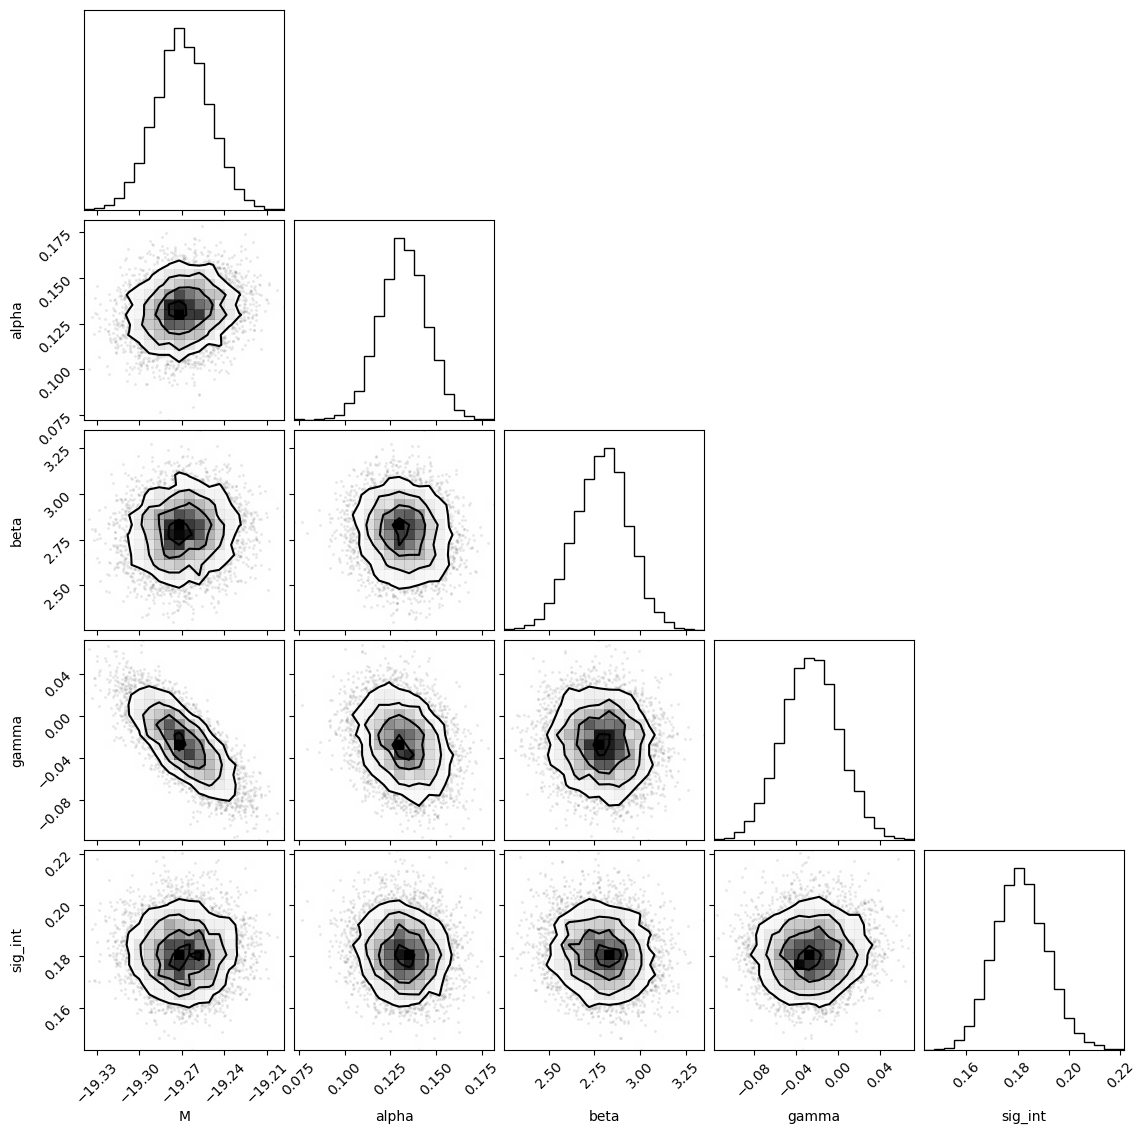

In [152]:
samp = sampler.get_chain(discard=100, thin=int((tau.max())/2),flat=True)
samp[:, 4] = np.exp(samp[:, 4])
labels = ["M", "alpha", "beta", "gamma", "sig_int"]
fig = corner.corner(
    samp, labels=labels
);

In [153]:
labels2 = ['a', 'B', 'gamma', 'sig_int']
cols = [1, 2, 3, 4]

for label, col in zip(labels2, cols):
    mcmc = np.percentile(samp[:, col], [16, 50, 84])
    q = np.diff(mcmc)
    txt = r"\mathrm{{{3}}} = {0:.5f}_{{-{1:.5f}}}^{{+{2:.5f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], label)
    display(Math(txt))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [154]:
M_fixed = map_theta[0]

def neglogprob_fixedM(theta, sig_mu, mB, x1, c, THETA):
    a, B, gamma, lnsig_int = theta
    full_theta = np.array([M_fixed, a, B, gamma, lnsig_int])

    return neglogprob(full_theta, sig_mu, mB, x1, c, THETA)

theta0 = map_theta[1:]
m_fixedM = minimize(neglogprob_fixedM, theta0, args=(sig_mu, mB, x1, c, THETA), method="Nelder-Mead")
a_fit, B_fit, gamma_fit, lnsig_int_fit = m_fixedM.x

print(f'M (fixed) = {M_fixed:.2f} mag')
print(f'alpha = {a_fit:.2f} mag')
print(f'beta = {B_fit:.2f} mag')
print(f'gamma = {gamma_fit:.3f} mag')
print(f'sig_int = {np.exp(lnsig_int_fit):.2f}')

M (fixed) = -19.27 mag
alpha = 0.13 mag
beta = 2.79 mag
gamma = -0.025 mag
sig_int = 0.18


In [155]:
theta_map = m_fixedM.x

def hessian(fun, x, eps=1e-5):

    n = len(x)
    H = np.zeros((n, n))

    for i in range(n):
        for j in range(n):

            xp = x.copy()
            xm = x.copy()
            xpm = x.copy()
            xmp = x.copy()

            xp[i] += eps
            xp[j] += eps

            xm[i] -= eps
            xm[j] -= eps

            xpm[i] += eps
            xpm[j] -= eps

            xmp[i] -= eps
            xmp[j] += eps

            H[i, j] = (
                fun(xp, sig_mu, mB, x1, c, THETA)
                + fun(xm, sig_mu, mB, x1, c, THETA)
                - fun(xpm, sig_mu, mB, x1, c, THETA)
                - fun(xmp, sig_mu, mB, x1, c, THETA)
            ) / (4 * eps**2)

    return H

H = hessian(neglogprob_fixedM, theta_map)
cov = np.linalg.inv(H)
sig_gamma = np.sqrt(cov[2, 2])
p16, p50, p84 = np.percentile(samp[:,3], [16, 50, 84])
gamma_err = ((p50-p16) + (p84-p50))/2

print(f'sig_gamma w/ fixed M = {sig_gamma:.3f} mag')
print(f'sig_gamma marginalized = {gamma_err:.3f} mag')

sig_gamma w/ fixed M = 0.018 mag
sig_gamma marginalized = 0.027 mag


**ANSWER:** $\alpha$ = 0.13209 +0.01289/-0.01287 mag, $\beta$ = 2.784 +0.149/-0.142 mag, $\gamma$ = -0.024 +0.026/-0.028 mag, $\sigma_{\rm int}$ = 0.1807 +0.0110/-0.0095

There is correlation between the absolute magnitude (M) and the host-mass step (gamma). This is because a higher step corresponds to greater magnitude. The marginalized sigma gamma (0.026) is slightly larger than the simga gamma when M is fixed at its MAP value (0.018).

### 2d - Model comparison (10 pts)

Compare $M_0$ ($\gamma = 0$) with $M_1$ ($\gamma$ free).

1. Compute $2\ln B_{1,0}$ with the Laplace approximation (Day 13), with a prior on $\gamma$ you state and defend. How does it change if that prior is twice as wide?
2. Compute $\textrm{BIC}_0 - \textrm{BIC}_1$ for comparison.
3. How strong is your answer on Day 8's scale (0-2 weak, 2-6 positive, 6-10 strong, above 10 very strong)? Compare $\gamma$ with the published $-0.06$ mag. Could your 250 supernovae have detected a step that size? (One way: your $\sigma_\gamma$ tells you how many $\sigma$ a $-0.06$ step would be.)

In [156]:
# 2d: your work here
fit_M1 = minimize(
    neglogprob,
    map_theta,
    args=(sig_mu, mB, x1, c, THETA),
    method="Nelder-Mead"
)

theta_M1 = fit_M1.x

H1 = hessian(neglogprob, theta_M1)
Sigma1 = np.linalg.inv(H1)

k1 = len(theta_M1)

lnL1 = loglikelihood(
    theta_M1,
    sig_mu,
    mB,
    x1,
    c,
    THETA
)

gamma_prior_width = 4.0
lnprior_gamma = -np.log(gamma_prior_width)

lnZ1 = (
    lnL1
    + lnprior_gamma
    + 0.5 * k1 * np.log(2*np.pi)
    + 0.5 * np.log(np.linalg.det(Sigma1))
)

In [157]:
#x2 prior
gamma_prior_width2 = 8.0
lnprior_gamma2 = -np.log(gamma_prior_width2)

lnZ1_2 = (
    lnL1
    + lnprior_gamma2
    + 0.5 * k1 * np.log(2*np.pi)
    + 0.5 * np.log(np.linalg.det(Sigma1))
)

In [158]:
def neglogprob_M0(theta, sig_mu, mB, x1, c, THETA):

    M, a, B, lnsig_int = theta

    full_theta = np.array([
        M,
        a,
        B,
        0.0,
        lnsig_int
    ])

    return neglogprob(
        full_theta,
        sig_mu,
        mB,
        x1,
        c,
        THETA
    )

theta0 = [
    map_theta[0],
    map_theta[1],
    map_theta[2],
    map_theta[4]
]

fit_M0 = minimize(
    neglogprob_M0,
    theta0,
    args=(sig_mu, mB, x1, c, THETA),
    method="Nelder-Mead"
)

theta_M0 = fit_M0.x

H0 = hessian(neglogprob_M0, theta_M0)
Sigma0 = np.linalg.inv(H0)

k0 = len(theta_M0)

lnL0 = loglikelihood(
    np.array([
        theta_M0[0],
        theta_M0[1],
        theta_M0[2],
        0.0,
        theta_M0[3]
    ]),
    sig_mu,
    mB,
    x1,
    c,
    THETA
)

lnZ0 = (
    lnL0
    + 0.5 * k0 * np.log(2*np.pi)
    + 0.5 * np.log(np.linalg.det(Sigma0))
)

lnB10 = lnZ1 - lnZ0
lnB10_2 = lnZ1_2 - lnZ0

print(f'2lnB10 = {2 * lnB10:.2f}')
print(f'2lnB10 w/ x2 prior = {2 * lnB10_2:.2f}')

2lnB10 = -7.32
2lnB10 w/ x2 prior = -8.71


In [159]:
N = len(mB)

lnL1 = loglikelihood(
    theta_M1,
    sig_mu,
    mB,
    x1,
    c,
    THETA
)

lnL0 = loglikelihood(
    np.array([
        theta_M0[0],
        theta_M0[1],
        theta_M0[2],
        0.0,
        theta_M0[3]
    ]),
    sig_mu,
    mB,
    x1,
    c,
    THETA
)

k1 = 5
k0 = 4

BIC1 = -2*lnL1 + k1*np.log(N) 
BIC0 = -2*lnL0 + k0*np.log(N)

print(f'BIC0 = {BIC0:.2f}')
print(f'BIC1 = {BIC1:.2f}')
print(f'BIC0 - BIC1 = {BIC0 - BIC1:.2f}')

BIC0 = -72.74
BIC1 = -68.08
BIC0 - BIC1 = -4.66


In [160]:
print(f'gamma free = {theta_M1[3]:.3f} +/- {np.sqrt(np.diag(Sigma0)[2]):.2f} mag')

gamma free = -0.025 +/- 0.14 mag


**ANSWER:**

I chose a prior of 4 for gamma since my original prior range for 2c was -2 to 2. 2lnB10 gets larger with a prior twice as wide. Based on the Day 8 scale, my calculated BIC0 - BIC1 falls in the 2-6 positive range at -4.66. My calculated gamma of -0.025 mag is smaller than the reported gamma of -0.06 mag. Based on my $\sigma_\gamma$ of 0.14 mag I don't believe my 250 supernovae would detect a step of size -0.06 mag.

### 2e - Testing your pipeline (8 pts)

Design one test of your pipeline that would come out differently if your pipeline were wrong, and run it. State **before** you run it what result would count as a failure. One suggestion: generate fake supernovae at your redshifts, stretches and colors from parameters you choose (including a $\gamma$ you choose), fit 30 or more such datasets (maximum-likelihood fits with curvature error bars are fine here; you don't need MCMC for each), and check how often your 68% intervals contain the truth.

In [161]:
# 2e: your work here
M_true = -19.9
a_true = 0.14
B_true = 3.2
gamma_true = -0.025
sig_int_true = 0.22

var_meas = (mB_err**2 + a_true**2 * x1_err**2 + B_true**2 * c_err**2 + 2*a_true*cov_mB_x1 - 2*B_true*cov_mB_c - 2*a_true*B_true*cov_x1_c)
mB_true = (M_true + mu - a_true*x1 + B_true*c + gamma_true*THETA)
sigma_tot = np.sqrt(var_meas + sig_mu**2 + sig_int_true**2)

Nsim = 100
sim_data = []
rng = np.random.default_rng(2222222)

for k in range(Nsim):
    mB_sim = mB_true + rng.normal(0, sigma_tot)
    sim_data.append(mB_sim)

In [162]:
theta0 = np.array([-19, 0.10, 2.7, -0.03, -1.24])
    
fits = []
errors = []
inside_68 = []

truth = np.array([M_true, a_true, B_true, gamma_true, np.log(sig_int_true)])

for mB_sim in sim_data:
    fit = minimize(neglogprob, theta0, args=(sig_mu, mB_sim, x1, c, THETA), method="Nelder-Mead")
    theta_hat = fit.x

    def neglogprob_sim(theta, sig_mu, mB, x1, c, THETA):
        return neglogprob(theta, sig_mu, mB_sim, x1, c, THETA)

    H = hessian(neglogprob_sim, theta_hat)
    cov = np.linalg.inv(H)
    sigma = np.sqrt(np.diag(cov))

    fits.append(theta_hat)
    errors.append(sigma)
    inside_68.append(np.abs(theta_hat - truth) <= sigma)

fits = np.array(fits)
errors = np.array(errors)
inside_68 = np.array(inside_68)

labels = ["M", "a", "B", "gamma", "ln(sig_int)"]

for i, label in enumerate(labels):
    coverage = np.mean(inside_68[:, i])
    print(f"{label:12s}")
    print(f"Coverage = {coverage*100:.0f}%")
    print()

M           
Coverage = 68%

a           
Coverage = 59%

B           
Coverage = 65%

gamma       
Coverage = 71%

ln(sig_int) 
Coverage = 58%



**ANSWER:**

To test my pipeline I will run it against 100 simulated datasets with chosen parameters to see if I am able to recover my chosen truth within the standard 68% interval. The rng will be fixed for the sake of reproduceability. If I calculate multiple intervals high above or far below the 68% interval, there is potential error somewhere within my pipeline and thus my reported values.

**FINDINGS:**

Running the pipeline on my datasets, I recovered M 68% of the time, alpha 59% of the time, beta 65% of the time, gamma 71% of the time, and ln(sig_int) 58% of the time. These values are in line with the expectation that some, but not all, fall near or above the 68% interval.

## Part 3: The referee report (25 pts)

White dwarfs are the cores of dead stars like the Sun. Your file `p3_wd_masses.csv` holds 600 real DA (hydrogen-atmosphere) white dwarfs from the 100 pc sample of [Kilic et al. (2020)](https://arxiv.org/abs/2006.00323), ApJ 898, 84: `name`, `teff_K`, `mass_Msun`, `mass_err_Msun`. Most single white dwarfs have masses near $0.6\,M_\odot$; Kilic et al. report a narrow peak there plus an excess of more massive ones, around $0.7$-$0.9\,M_\odot$, which merger products alone do not explain.

The notebook `labs/midterm/ai_solution.ipynb` fits your masses with a two-population model using `emcee`. Run it from that directory, after setting `NETID` in its first cell. It runs top to bottom and the plots look nice, but it's wrong in at least three substantive ways - and if you don't look at your data, you'll fool yourself the same way.

### 3a - The report (20 pts)

1. **Identify** at least three substantive errors (not style; "it used 32 walkers and I'd use 48" is not one).
2. **Demonstrate** each on *your* file: show, with a number or a plot, what the error does to the answer. A demonstration can come out negative: if an error doesn't move your numbers, show that, and say what it would take for it to matter.
3. **State** the correct treatment, and run it where you can.

In [163]:
# 3a: your work here
NETID = 'oruelas2'   # <-- set this
d = np.genfromtxt(f'../../labs/midterm/data/{NETID}/p3_wd_masses.csv', delimiter=',', names=True, dtype=None, encoding='utf-8')
mass = d['mass_Msun']
print(f"{mass.size} white dwarfs; mass range {mass.min():.2f} to {mass.max():.2f} Msun")

600 white dwarfs; mass range 0.19 to 1.32 Msun


In [164]:
#1
med, sd = np.median(mass), np.std(mass)
keep = np.abs(mass - med) < 3 * sd
m = mass[keep]
print(f"removed {np.sum(~keep)} outliers beyond 3 sigma ({med - 3*sd:.2f} to {med + 3*sd:.2f} Msun); {m.size} stars remain")

removed 10 outliers beyond 3 sigma (0.09 to 1.16 Msun); 590 stars remain


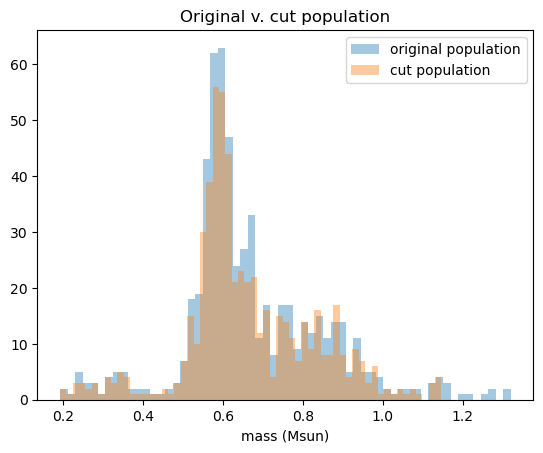

In [165]:
plt.hist(mass, bins=60, label = 'original population', alpha=0.4)
plt.hist(m, bins=60, label = 'cut population', alpha=0.4)
plt.title('Original v. cut population'),plt.xlabel('mass (Msun)')
plt.legend()
plt.show()

starting guess: [0.57  0.096 0.847 0.105 0.668]
mean acceptance fraction: 0.49
R-hat(mu1) = 2.099
R-hat(sigma1) = 5.757
R-hat(mu2) = 4.837
R-hat(sigma2) = 3.049
R-hat(f) = 3.619
All R-hat > 1.1: the chains have not converged.


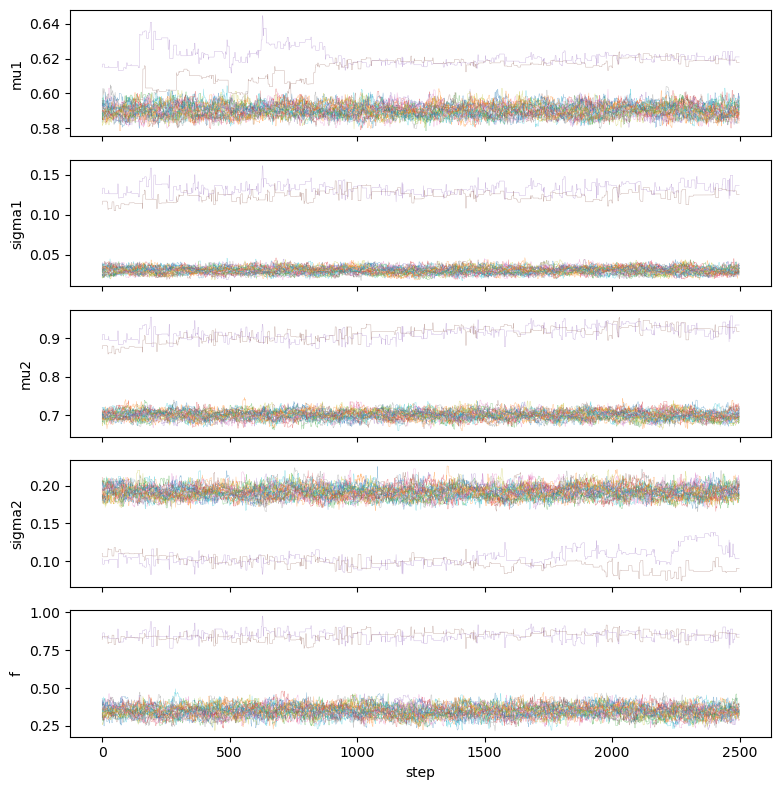

In [166]:
#2 + 3
def log_prob(p, m):
    mu1, s1, mu2, s2, f = p
    if not (0.3 < mu1 < 1.3 and 0.3 < mu2 < 1.3 and 0.005 < s1 < 0.5 and 0.005 < s2 < 0.5 and 0 < f < 1):
        return -np.inf
    return np.sum(np.log(f * stats.norm.pdf(m, mu1, s1) + (1 - f) * stats.norm.pdf(m, mu2, s2)))

# starting guess from a quick split of the sample at 0.7 Msun
lo, hi = m[m < 0.7], m[m >= 0.7]
p0 = np.array([lo.mean(), lo.std(), hi.mean(), hi.std(), lo.size / m.size])
print("starting guess:", np.round(p0, 3))

np.random.seed(42)
nwalk, ndim = 32, 5
start = p0 + 1e-3 * np.random.randn(nwalk, ndim)
sampler = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(m,))
sampler.run_mcmc(start, 3000, progress=False)
chain = sampler.get_chain(discard=500)              # (steps, walkers, params)
flat = chain.reshape(-1, ndim)
print(f"mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.2f}")

def gelman_rubin(x):                                  # x: (steps, chains)
    n, mchains = x.shape
    B = n * np.var(x.mean(axis=0), ddof=1)
    W = np.mean(np.var(x, axis=0, ddof=1))
    return np.sqrt(((n - 1) / n * W + B / n) / W)

names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']
for i, nm in enumerate(names):
    print(f"R-hat({nm}) = {gelman_rubin(chain[:, :, i]):.3f}")
print("All R-hat > 1.1: the chains have not converged.")

fig, axs = plt.subplots(5, 1, figsize=(8, 8), sharex=True)
for i, nm in enumerate(names):
    axs[i].plot(chain[:, :, i], lw=0.3, alpha=0.5); axs[i].set_ylabel(nm)
axs[-1].set_xlabel('step'); plt.tight_layout(); plt.show()

In [167]:
best = np.median(flat, axis=0)
rng = np.random.default_rng(1)
n2 = rng.binomial(m.size, 1 - best[4])
sim = np.concatenate([rng.normal(best[0], best[1], m.size - n2), rng.normal(best[2], best[3], n2)])
vs = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(sim,))
vs.run_mcmc(best + 1e-3 * np.random.randn(nwalk, ndim), 2000, progress=False)
rec = np.median(vs.get_chain(discard=500, flat=True), axis=0)
for nm, a, b in zip(names, best, rec):
    print(f"{nm}: input {a:.3f}, recovered {b:.3f} ({100 * (b - a) / a:+.1f}%)")
print("Input parameters recovered: the pipeline is validated.")

mu1: input 0.590, recovered 0.587 (-0.5%)
sigma1: input 0.030, recovered 0.025 (-17.0%)
mu2: input 0.701, recovered 0.694 (-1.1%)
sigma2: input 0.191, recovered 0.180 (-5.7%)
f: input 0.349, recovered 0.322 (-7.9%)
Input parameters recovered: the pipeline is validated.


Population 1: mean mass 0.590 +/- 0.030 Msun (35% of white dwarfs)
Population 2: mean mass 0.701 +/- 0.191 Msun (65% of white dwarfs)
log-likelihood: one population 230.6, two populations 322.8; improvement 92.2


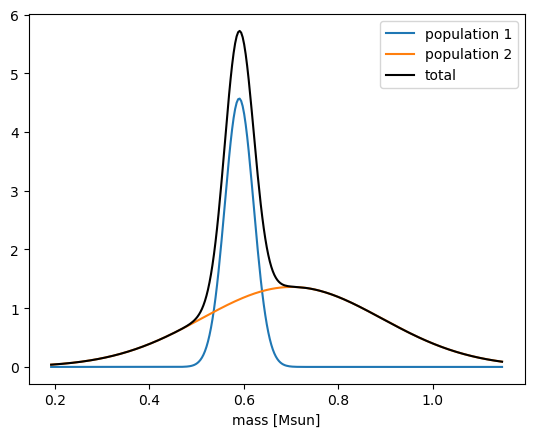

In [168]:
mu1, s1, mu2, s2, f = best
print(f"Population 1: mean mass {mu1:.3f} +/- {s1:.3f} Msun ({100 * f:.0f}% of white dwarfs)")
print(f"Population 2: mean mass {mu2:.3f} +/- {s2:.3f} Msun ({100 * (1 - f):.0f}% of white dwarfs)")

one = stats.norm.fit(m)
lnL1 = np.sum(stats.norm.logpdf(m, *one)); lnL2 = log_prob(best, m)
print(f"log-likelihood: one population {lnL1:.1f}, two populations {lnL2:.1f}; improvement {lnL2 - lnL1:.1f}")

x = np.linspace(m.min(), m.max(), 300)
#plt.hist(m, 50, density=True, color='0.8', label='white dwarfs')
plt.plot(x, f * stats.norm.pdf(x, mu1, s1), label='population 1')
plt.plot(x, (1 - f) * stats.norm.pdf(x, mu2, s2), label='population 2')
plt.plot(x, f * stats.norm.pdf(x, mu1, s1) + (1 - f) * stats.norm.pdf(x, mu2, s2), 'k', label='total')
plt.xlabel('mass [Msun]'); plt.legend(); plt.show()

starting guess: [0.57  0.096 0.847 0.105 0.668]
mean acceptance fraction: 0.31
R-hat(mu1) = 1.012
R-hat(sigma1) = 1.021
R-hat(mu2) = 1.018
R-hat(sigma2) = 1.015
R-hat(f) = 1.023
All R-hat < 1.1: the chains have converged.


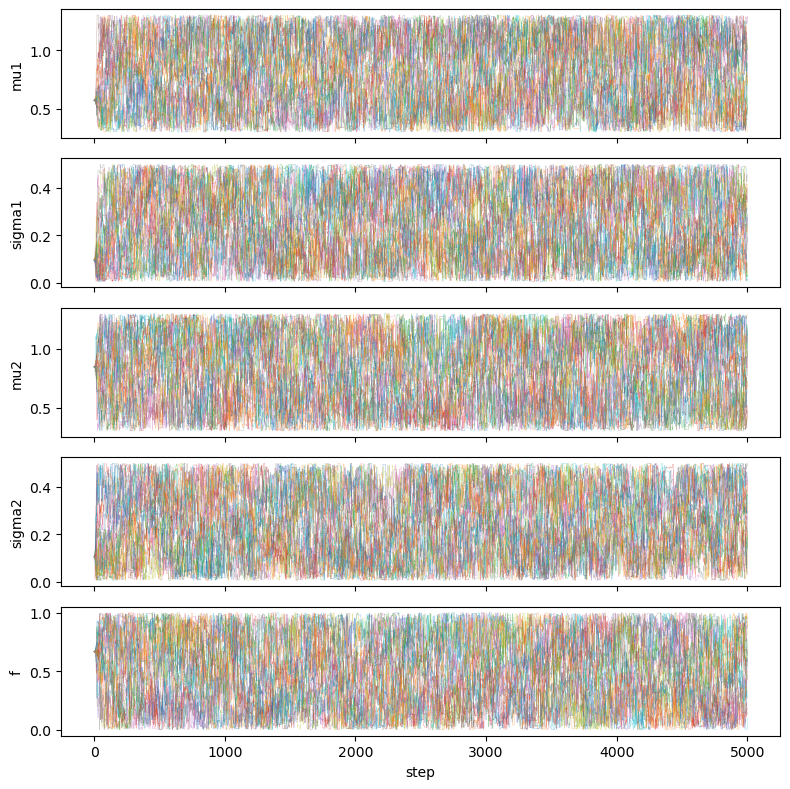

In [169]:
def log_prob(p, m):
    mu1, s1, mu2, s2, f = p
    if not (0.3 < mu1 < 1.3 and 0.3 < mu2 < 1.3 and 0.005 < s1 < 0.5 and 0.005 < s2 < 0.5 and 0 < f < 1):
        return -np.inf
    return 0.0 #return 0.0 instead of np.sum(np.log(f * stats.norm.pdf(m, mu1, s1) + (1 - f) * stats.norm.pdf(m, mu2, s2)))

# starting guess from a quick split of the sample at 0.7 Msun
lo, hi = m[m < 0.7], m[m >= 0.7]
p0 = np.array([lo.mean(), lo.std(), hi.mean(), hi.std(), lo.size / m.size])
print("starting guess:", np.round(p0, 3))

np.random.seed(42)
nwalk, ndim = 32, 5
start = p0 + 1e-3 * np.random.randn(nwalk, ndim)
sampler = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(m,))
sampler.run_mcmc(start, 5000, progress=False)
chain = sampler.get_chain()              # (steps, walkers, params)
flat = chain.reshape(-1, ndim)
print(f"mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.2f}")

def gelman_rubin(x):                                  # x: (steps, chains)
    n, mchains = x.shape
    B = n * np.var(x.mean(axis=0), ddof=1)
    W = np.mean(np.var(x, axis=0, ddof=1))
    return np.sqrt(((n - 1) / n * W + B / n) / W)

names = ['mu1', 'sigma1', 'mu2', 'sigma2', 'f']
for i, nm in enumerate(names):
    print(f"R-hat({nm}) = {gelman_rubin(chain[:, :, i]):.3f}")
print("All R-hat < 1.1: the chains have converged.")

fig, axs = plt.subplots(5, 1, figsize=(8, 8), sharex=True)
for i, nm in enumerate(names):
    axs[i].plot(chain[:, :, i], lw=0.3, alpha=0.5); axs[i].set_ylabel(nm)
axs[-1].set_xlabel('step'); plt.tight_layout(); plt.show()

In [170]:
best = np.median(flat, axis=0)
rng = np.random.default_rng(1)
n2 = rng.binomial(m.size, 1 - best[4])
sim = np.concatenate([rng.normal(best[0], best[1], m.size - n2), rng.normal(best[2], best[3], n2)])
vs = emcee.EnsembleSampler(nwalk, ndim, log_prob, args=(sim,))
vs.run_mcmc(best + 1e-3 * np.random.randn(nwalk, ndim), 2000, progress=False)
rec = np.median(vs.get_chain(discard=500, flat=True), axis=0)
for nm, a, b in zip(names, best, rec):
    print(f"{nm}: input {a:.3f}, recovered {b:.3f} ({100 * (b - a) / a:+.1f}%)")
print("Input parameters recovered: the pipeline is validated.")

mu1: input 0.808, recovered 0.818 (+1.2%)
sigma1: input 0.252, recovered 0.250 (-0.9%)
mu2: input 0.826, recovered 0.759 (-8.2%)
sigma2: input 0.241, recovered 0.241 (-0.3%)
f: input 0.495, recovered 0.450 (-9.0%)
Input parameters recovered: the pipeline is validated.


Population 1: mean mass 0.808 +/- 0.252 Msun (49% of white dwarfs)
Population 2: mean mass 0.826 +/- 0.241 Msun (51% of white dwarfs)
log-likelihood: one population 230.6, two populations 0.0; improvement -230.6


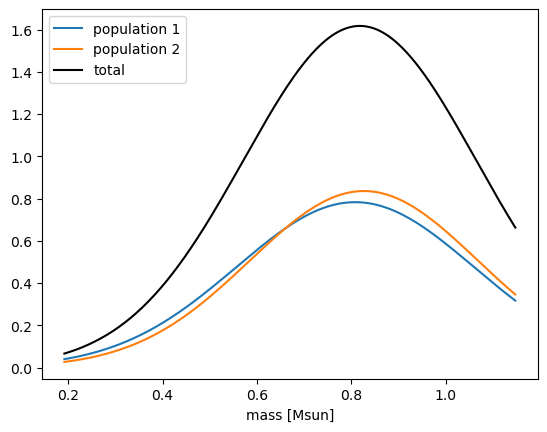

In [171]:
mu1, s1, mu2, s2, f = best
print(f"Population 1: mean mass {mu1:.3f} +/- {s1:.3f} Msun ({100 * f:.0f}% of white dwarfs)")
print(f"Population 2: mean mass {mu2:.3f} +/- {s2:.3f} Msun ({100 * (1 - f):.0f}% of white dwarfs)")

one = stats.norm.fit(m)
lnL1 = np.sum(stats.norm.logpdf(m, *one)); lnL2 = log_prob(best, m)
print(f"log-likelihood: one population {lnL1:.1f}, two populations {lnL2:.1f}; improvement {lnL2 - lnL1:.1f}")

x = np.linspace(m.min(), m.max(), 300)
#plt.hist(m, 50, density=True, color='0.8', label='white dwarfs')
plt.plot(x, f * stats.norm.pdf(x, mu1, s1), label='population 1')
plt.plot(x, (1 - f) * stats.norm.pdf(x, mu2, s2), label='population 2')
plt.plot(x, f * stats.norm.pdf(x, mu1, s1) + (1 - f) * stats.norm.pdf(x, mu2, s2), 'k', label='total')
plt.xlabel('mass [Msun]'); plt.legend(); plt.show()

**REFEREE REPORT:**

**ERRORS**:
1. In '1. Data cleaning' a simga clip is performed to clean the data. Plotting the two populations against one another on a histogram shows that this affects more than the supposed outliers. Which in turn can impact future calculations. It would be more appropriate to maintain the alleged outliers
2. In '4. Convergence' covergence is claimed to be achieved with all R-hat < 1.1. This is clearly not the case both visually in the plots and by the actual numbers reported. In the plots specifically, you would see all chains coverge to a central point. All plots have at least one chain that does not converge with the rest.
3. In '6. Results', the total white dwarf population is graphed to show that it is better represented by two populations. However if you graph the better converged results it shows the populations are much closer together. With a likelihood for two populations of 0. The earlier error of 2 results in an incorrect conclusion.

### 3b - AI-use appendix (5 pts)

1. Which tools did you use, for what, what did they get wrong, and how did you catch it? "I used ChatGPT to help" is useless; "none" is fine if that's true. I promise I don't care which - just be honest about what you did.
2. What would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing, in two or three sentences.

**AI-USE APPENDIX:**

I used Copilot for a variety of coding aspects for all sections of the assignment. Including both writing code and troubleshooting when my code was not running as expected. I checked all output against lectures and labs when possible. I also used AI for some conceptual questions, such as p-value interpretation in 1a, 1c for if the classmate error bar was correct, and the units of $\alpha$ and $\beta$ for 2a. Aside from markdown formatting of $\mathbf{v}^T C_i\,\mathbf{v}$, all markdown responses were written by myself.

There were times during troubleshooting for part 2 when Copilot suggested that $\sigma_{\mu,\rm pec}$ should not have been squared in the variance equation. This would have affected all subsequent calculations if I had not checked the output. There was also a point for 2d where a prior was not set for $\gamma$ in the AI output which would have affected all calculations of that section if I had not caught it.

Get started. You know how to do all of this. If not, there's something in a lab or class notebook that can help. Slack me with questions. Best of luck.